# <span style="color:green"> Numerical Simulation Laboratory (NSL) </span>
## <span style="color:blue">  Numerical exercises 3</span>

### Exercise 03.1 <span style="color:red"> Plain vanilla option pricing </span>

Black-Scholes theory assumes that the time evolution of the asset price is stochastic and exhibits geometric Brownian motion (GBM) with constant risk-free interest rate $r$ and volatility $\sigma$.

Black-Scholes <span style="color:blue"> analytic solution </span> for the price at time t<T:
- European Call-option price:
$$ C\left[ S(t),t \right] = S(t) N(d_1) -K e^{-r(T-t)} N(d_2) $$
- European Put-option price:
$$ P\left[ S(t),t \right] = S(t) \left[ N(d_1)-1\right] -K e^{-r(T-t)} \left[ N(d_2)-1\right]$$

where 
$$d_1 = \frac{1}{\sigma\sqrt{T-t}}\left[ \ln \left( \frac{S(t)}{K} \right) + \left( r+\frac{\sigma^2}{2} (T-t) \right)\right]$$

where $d_2 = d_1 - \sigma\sqrt{T-t}$, and where
$$ N(x) = \int_{-\infty}^{x} dz \, e^{-\frac{z^2}{2}} = \frac{1}{2} \left[ 1+ {\rm erf} \left( \frac{x}{\sqrt{2}}\right) \right]$$
is the cumulative of Gaussian $\sim \mathcal{N}(\mu=0,\sigma^2=1)$,
and where
$${\rm erf}(x) = \frac{2}{\sqrt{\pi}}\int_{0}^{x} dz \, e^{-z^2}$$

By using the following parameters: 
- asset price at $t=0$: $S(0)=100$
- delivery time: $T=1$
- strike price: $K=100$
- risk-free interest rate: $r=0.1$
- volatility: $\sigma=0.25$

compute at time $t=0$ **via Monte Carlo** the European call-option price, $C[S(0),0]$, and put-option price, $P[S(0),0]$:

1. <span style="color:red"> By sampling **directly** the final asset price $S(T)$</span> for a $GBM(r,\sigma^2)$
2. <span style="color:red"> By sampling the discretized $GBM(r,\sigma^2)$ path of the asset price</span> 
dividing $[0,T]$ in $10^2$ time intervals: $S(0)$, $S(t_1)$, $S(t_2)$, ... up to $S(t_{100}=T=1)$


Remember that given an asset price $S\sim GBM(\mu,\sigma^2)$, with initial value $S(0)$, then
$$S(t) = S(0) \exp\left[ \left(\mu-\frac{1}{2}\sigma^2\right)t+\sigma W(t)\right]$$
where $W(t)\sim\mathcal{N}(0,t)$.
Moreover, since the increments of $W$ are independent and normally distributed, the simple recursive procedure for sampling discretized values of $S\sim GBM(\mu,\sigma^2)$ at $t_1 < t_2 < … < t_n$ is:
$$S(t_{i+1}) = S(t_i) \exp\left[ \left(\mu-\frac{1}{2}\sigma^2\right)(t_{i+1}-t_i)
    +\sigma Z_{i+1}\sqrt{t_{i+1}-t_i}\right]$$
with $Z_i \sim \mathcal{N}(0,1)$


<span style="color:red">Make four pictures for the estimation of the European call-option prices, $C[S(0),0]$ (direct and discretized), and put-option prices, $P[S(0),0]$ (direct and discretized), with their uncertainties </span> with a large number of asset prices at time $t=T$, say $M\ge 10^4$, as a function of the number of blocks, $N$</font>. <span style="color:blue"> As usual, in computing statistical uncertainties, use data blocking.</span>

### For comparison, Black-Scholes analytic solution:

In [1]:
import scipy
from scipy.special import erf
import numpy
from numpy import exp
from numpy.lib.scimath import log, sqrt

# data
S0 = 100.
K = 100.
T = 1.
r = 0.1
sigma = 0.25
t=0

def N(x):
    return 0.5 * (1. + erf(x / sqrt(2.)))

def black_scholes(S0, K, T, r, sigma):
    d1 = 1./(sigma * sqrt(T)) * (log(S0 / K) + (r + (sigma**2) / 2.) * T)
    d2 = d1 - sigma * sqrt(T)
    C = S0 * N(d1) - K * exp(-r * T) * N(d2)
    P = S0 *(N(d1) - 1.) - K * exp(-r * T) * (N(d2)-1.)
    return C, P

if __name__ == "__main__":
    call, put = black_scholes(S0, K, T, r, sigma)
    print(" == BLACK-SCHOLES ==")
    print("call: ", call)
    print("put: ", put)

 == BLACK-SCHOLES ==
call:  14.975790778311286
put:  5.4595325819072364


# <span style="color:green"> RESULTS: </span>

In this notebook we will use the Black-Scholes theory for the evolution of market prices to compute, via Monte Carlo, the price of European call and put options with two methods, direct and discretized sampling, and then we will compare the results with the analytic Black-Scholes solution.

### Options and payoff
A European call (or put) option gives the right, but not the obligation, to buy (or sell) an asset at the delivery time $T$ at a fixed strike price $K$. If at time $T$ the asset price is $S(T)$, the holder gains the payoff
$$
\max\{0,\,S(T)-K\}\quad\text{(call)},\qquad \max\{0,\,K-S(T)\}\quad\text{(put)},
$$
because the option is exercised only if it is convenient. For example, with $K=100$: if $S(T)=120$ the call pays $20$ and the put $0$, while if $S(T)=80$ the call pays $0$ and the put $20$. Since $S(T)$ is random, the price of the option at $t=0$ is the expected payoff discounted to $t=0$ with the risk-free rate:
$$
C[S(0),0]=e^{-rT}\,\big\langle \max\{0,\,S(T)-K\}\big\rangle ,\qquad
P[S(0),0]=e^{-rT}\,\big\langle \max\{0,\,K-S(T)\}\big\rangle .
$$
In this expectation $S(T)$ must be sampled from a geometric Brownian motion $GBM(r,\sigma^2)$, whcih means with the drift equal to the risk-free rate $r$ and not to the real drift of the market: in this way the discounted price $e^{-rt}S(t)$ has constant mean $S(0)$ and the real drift does not enter the price.

### Monte Carlo estimate
We estimate the two expectations as the average of the discounted payoff over $M=10^5$ asset prices $S(T)$, with the uncertainty computed by data blocking. The two ways of sampling $S(T)$ are:

#### Direct sampling
The asset price is sampled as follows:
$$S(T)=S(0)\exp\big[(r-\sigma^2/2)T+\sigma\sqrt{T}\,Z\big]$$
with one $Z\sim\mathcal{N}(0,1)$ for each price.

If we take $S(0)=100$, $K=100$, $r=0.1$, $\sigma=0.25$ and $T=1$, we have $(r-\sigma^2/2)T=0.06875$ and $\sigma\sqrt{T}=0.25$.

For $Z=0$ the asset price is then $S(T)=100\,e^{0.06875}=107.12$: the call pays $7.12$, which discounted is $7.12\,e^{-0.1}=6.44$, while the put pays nothing.

For a positive fluctuation, $Z=+1$, we get $S(T)=100\,e^{0.31875}=137.54$ and a discounted call payoff of $33.97$, with the put again at zero.

For a negative fluctuation, $Z=-1$, we get $S(T)=100\,e^{-0.18125}=83.42$: now the call pays nothing and the put pays $16.58$, that is $15.00$ discounted. The call pays only if the asset price ends above $K$ and the put only if it ends below $K$.

The estimate of the option price is the average of the discounted payoffs over all the $M=10^5$ asset prices, and not over three values as in this example.

#### Discretized sampling
With discretized sampling we take $100$ steps of the recursive formula with $\Delta t=T/100$, hence $100$ values of $Z$ for each price.

With $\Delta t=0.01$ each step multiplies the price by $\exp\big[0.00069+0.025\,Z_i\big]$, which means by $1.026$ if $Z_i=+1$ and by $0.976$ if $Z_i=-1$. The price $S(T)$ is $S(0)$ multiplied by the $100$ factors of the $100$ steps.

For constant $r$ and $\sigma$ the two procedures sample exactly the same distribution: $\ln S(T)$ is $\ln S(0)$ plus the sum of $100$ independent Gaussian increments of mean $(r-\sigma^2/2)\Delta t$ and variance $\sigma^2\Delta t$, which is a Gaussian of mean $(r-\sigma^2/2)T$ and variance $\sigma^2T$, exactly as in the direct sampling. The discretization therefore introduces no systematic error, and the only difference is the cost: $100$ times more random numbers for each price.

### Data blocking
As usual the uncertainty is computed with data blocking: the $M=10^5$ prices are grouped in $N=100$ blocks of $L=M/N=10^3$ prices each. Each block gives one average of the discounted payoff, and after $n$ blocks the estimate of the price is the mean of the $n$ block averages, with an uncertainty given by their standard deviation divided by $\sqrt{n-1}$.

In [2]:
import numpy as np
import matplotlib.pyplot as plt

In [3]:
files = [
    ("./OUTPUT/call_direct.dat", "Call - Direct Sampling", call),
    ("./OUTPUT/put_direct.dat", "Put - Direct Sampling", put),
    ("./OUTPUT/call_discrete.dat", "Call - Discrete Sampling", call),
    ("./OUTPUT/put_discrete.dat", "Put - Discrete Sampling", put)
]

The same values of $S(T)$ are used for the call and for the put. The main parts of the code are shown below: the two ways of sampling $S(T)$, the discounted payoffs and their data blocking:
<small>

```cpp
// (1) direct sampling
double Z  = rnd.Gauss(0,1);
double ST = S0*exp((r - 0.5*sigma*sigma)*T + sigma*Z*sqrt(T));

// (2) discretized path: 100 steps with dt = T/100
double ST = S0;
for(int j=1; j<=100; j++){
    double Z = rnd.Gauss(0,1);
    ST = ST * exp((r - 0.5*sigma*sigma)*dt + sigma*Z*sqrt(dt));
}

// discounted payoffs, added to the data blocking of the call and of the put
// (one pair of blockers for each sampling method)
double call = exp(-r*T) * max(0.0, ST-k);
double put  = exp(-r*T) * max(0.0, k-ST);
blocker_call.AddMeasure(call);
blocker_put.AddMeasure(put);
```

</small>

Here <small><code>rnd.Gauss(0,1)</code></small> generates $Z\sim\mathcal{N}(0,1)$, <small><code>k</code></small> is the strike price $K$ and <small><code>dt</code></small> is $\Delta t=T/100$. The call and the put are evaluated on the same <small><code>ST</code></small>. <small><code>AddMeasure</code></small> adds each discounted payoff to the current block of $L=10^3$ prices. 

The following figures show the estimate of the option price as a function of the number of blocks $N$, with its uncertainty given by data blocking, for the call and the put and for the two ways of sampling. The estimates are compared with the Black-Scholes analytic values, $C[S(0),0]=14.9758$ and $P[S(0),0]=5.4595$.

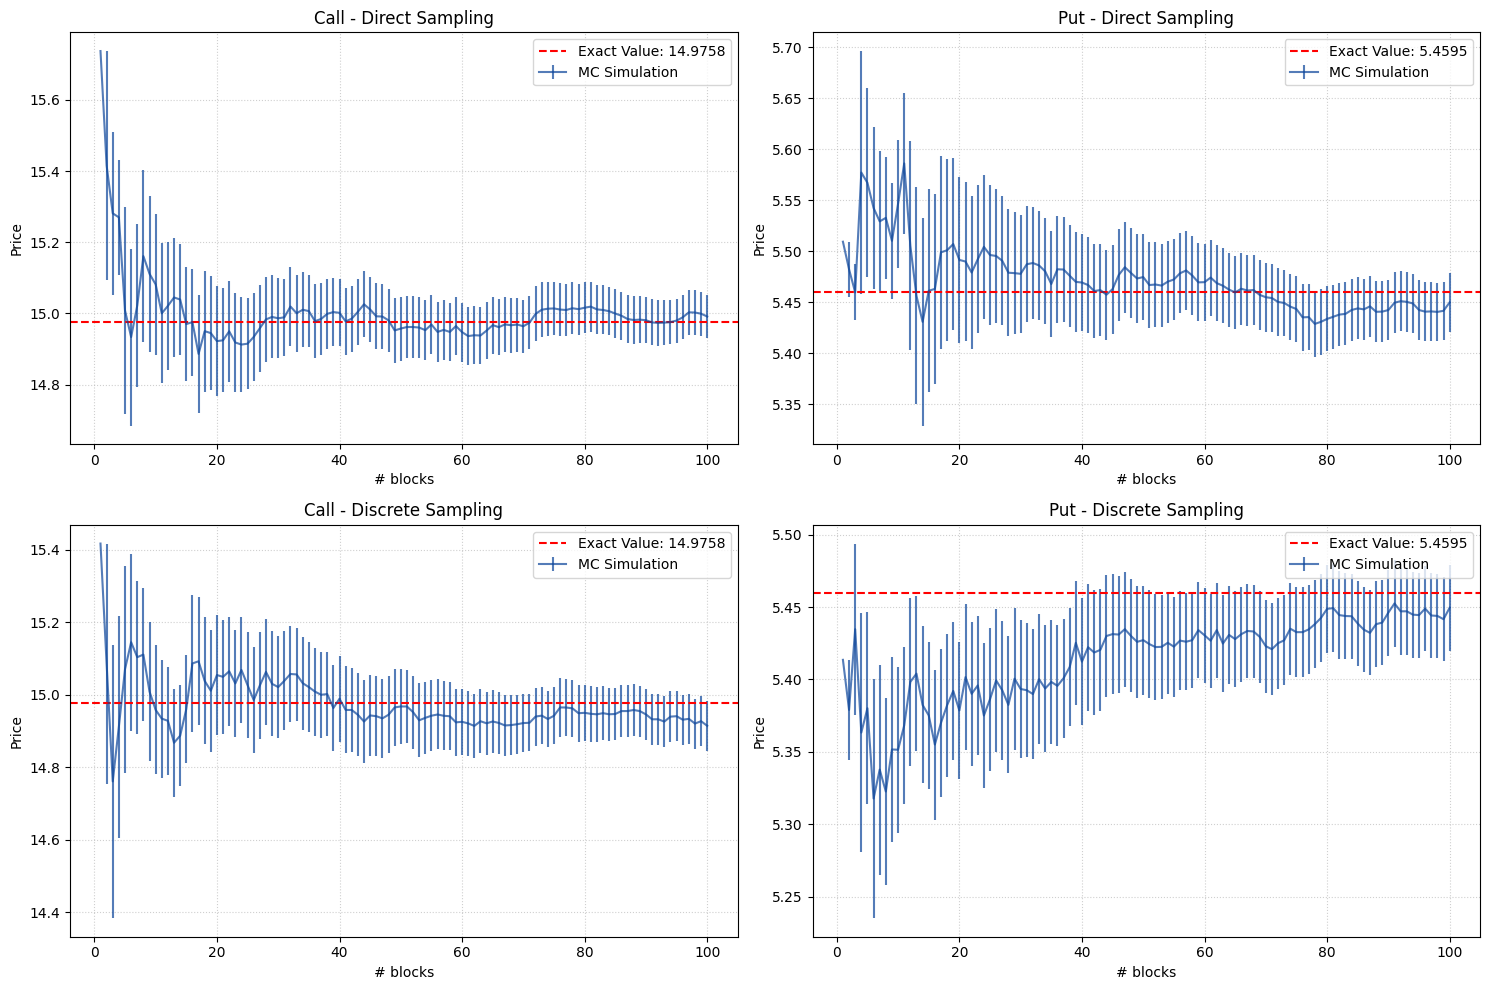

In [4]:
plt.figure(figsize=(15, 10))

for i, (filename, title, theoretical) in enumerate(files):
    try:
        # load data (n_block, meam, error)
        n, mean, error = np.loadtxt(filename, unpack=True)
        
        plt.subplot(2, 2, i+1)
        plt.errorbar(n, mean, yerr=error, label='MC Simulation', color="#0c459a", alpha=0.7)
        plt.axhline(y=theoretical, color='red', linestyle='--', label=f'Exact Value: {theoretical:.4f}')
        
        plt.title(title)
        plt.xlabel('# blocks')
        plt.ylabel('Price')
        plt.grid(True, linestyle=':', alpha=0.6)
        plt.legend()
        
    except FileNotFoundError:
        print(f"Error: file {filename} has not been found.")

plt.tight_layout()
plt.show()

With few blocks the estimates fluctuate strongly and have large error bars. As $N$ increases the uncertainty decreases as $1/\sqrt{N}$ and the estimates settle around the Black-Scholes values: in all four cases the exact value lies within about one standard deviation of the final estimate, so the simulation is compatible with the analytic solution.

As expected, direct sampling and discretized path give compatible results and the differences between the curves could be attributed to statistical fluctuations, since the two simulations use different random numbers. What is different is that the discretized path requires $100$ times more random numbers, so for these options direct sampling is the convenient choice. The discretized path would be needed for path-dependent options, or if $r$ or $\sigma$ were not constant.